<a href="https://colab.research.google.com/github/subhramannil/MY_LEARNING/blob/main/GDA_Breast_Cancer_GDA_From_Scratch_Updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target
df["diagnosis"] = pd.Series(data.target).map({0: "malignant", 1: "benign"})

print("Dataset shape (rows, columns):", df.shape)
print("\nTarget mapping:")
print("0 =", data.target_names[0], "| 1 =", data.target_names[1])
print("\nTarget counts:")
print(df["diagnosis"].value_counts())
display(df.head())

Dataset shape (rows, columns): (569, 32)

Target mapping:
0 = malignant | 1 = benign

Target counts:
diagnosis
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,malignant


In [2]:
X = df[data.feature_names].to_numpy(dtype=float)
y = df["target"].to_numpy(dtype=int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training features:", X_train.shape)
print("Training labels:  ", y_train.shape)
print("Test features:    ", X_test.shape)
print("Test labels:      ", y_test.shape)
print("\nTraining class counts (0=malignant, 1=benign):", np.bincount(y_train))
print("Test class counts (0=malignant, 1=benign):", np.bincount(y_test))

Training features: (455, 30)
Training labels:   (455,)
Test features:     (114, 30)
Test labels:       (114,)

Training class counts (0=malignant, 1=benign): [170 285]
Test class counts (0=malignant, 1=benign): [42 72]


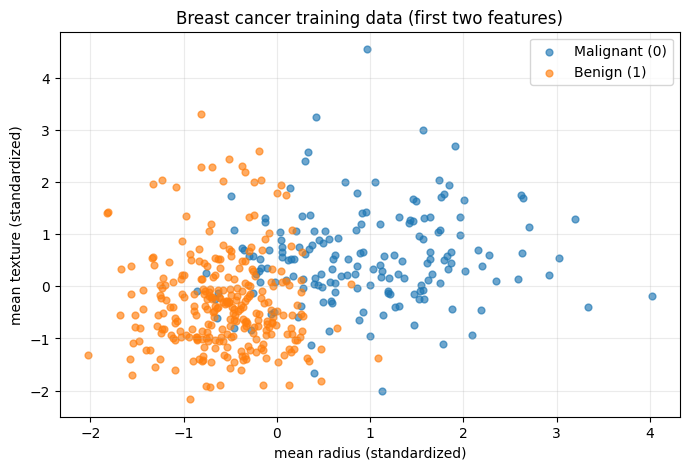

In [3]:
plt.figure(figsize=(8, 5))
for label, name in [(0, "Malignant (0)"), (1, "Benign (1)")]:
    mask = y_train == label
    plt.scatter(X_train[mask, 0], X_train[mask, 1], label=name, alpha=0.65, s=24)
plt.xlabel(data.feature_names[0] + " (standardized)")
plt.ylabel(data.feature_names[1] + " (standardized)")
plt.title("Breast cancer training data (first two features)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [4]:
class GaussianDiscriminantAnalysis:

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)

        if not np.array_equal(np.unique(y), np.array([0, 1])):
            raise ValueError("This example expects class labels 0 and 1.")

        #prior probability of class 1.
        self.phi = np.mean(y == 1)

        # mean feature vector for each class.
        self.mu_0 = X[y == 0].mean(axis=0)
        self.mu_1 = X[y == 1].mean(axis=0)

        # Centre each example using the mean of its own class.
        centred = X.copy()
        centred[y == 0] -= self.mu_0
        centred[y == 1] -= self.mu_1

        # Maximum-likelihood estimate.
        m = X.shape[0]
        self.sigma = (centred.T @ centred) / m

        sign, self.log_det_sigma = np.linalg.slogdet(self.sigma)
        if sign <= 0:
            raise ValueError("Covariance matrix must be positive definite.")

        self.inv_sigma = np.linalg.inv(self.sigma)
        self.n_features = X.shape[1]
        return self

    def _log_gaussian_density(self, X, mean):
        differences = X - mean
        distance = np.einsum("ij,jk,ik->i", differences, self.inv_sigma, differences)
        constant = self.n_features * np.log(2 * np.pi) + self.log_det_sigma
        return -0.5 * (constant + distance)

    def predict_log_scores(self, X):
        X = np.asarray(X, dtype=float)
        score_0 = self._log_gaussian_density(X, self.mu_0) + np.log(1 - self.phi)
        score_1 = self._log_gaussian_density(X, self.mu_1) + np.log(self.phi)
        return np.column_stack((score_0, score_1))

    def predict(self, X):
        return np.argmax(self.predict_log_scores(X), axis=1)

In [5]:
gda = GaussianDiscriminantAnalysis()
gda.fit(X_train, y_train)

print("Estimated P(y = 1) [benign]:", round(gda.phi, 3))
print("Mean vector shape for class 0 (malignant):", gda.mu_0.shape)
print("Mean vector shape for class 1 (benign):   ", gda.mu_1.shape)
print("Shared covariance matrix shape:", gda.sigma.shape)

Estimated P(y = 1) [benign]: 0.626
Mean vector shape for class 0 (malignant): (30,)
Mean vector shape for class 1 (benign):    (30,)
Shared covariance matrix shape: (30, 30)


In [6]:
y_pred = gda.predict(X_test)
print("First 15 true labels:     ", y_test[:15])
print("First 15 predicted labels:", y_pred[:15])
print("Labels: 0=malignant, 1=benign")

First 15 true labels:      [0 1 0 1 0 1 1 0 0 0 1 0 1 0 0]
First 15 predicted labels: [0 1 0 1 0 1 1 0 0 0 1 0 1 0 0]
Labels: 0=malignant, 1=benign


In [7]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.3f} ({accuracy * 100:.1f}%)")
print("\nConfusion matrix (rows=true, columns=predicted; 0=malignant, 1=benign):")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["malignant", "benign"], zero_division=0))

Test accuracy: 0.956 (95.6%)

Confusion matrix (rows=true, columns=predicted; 0=malignant, 1=benign):
[[38  4]
 [ 1 71]]

Classification report:
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



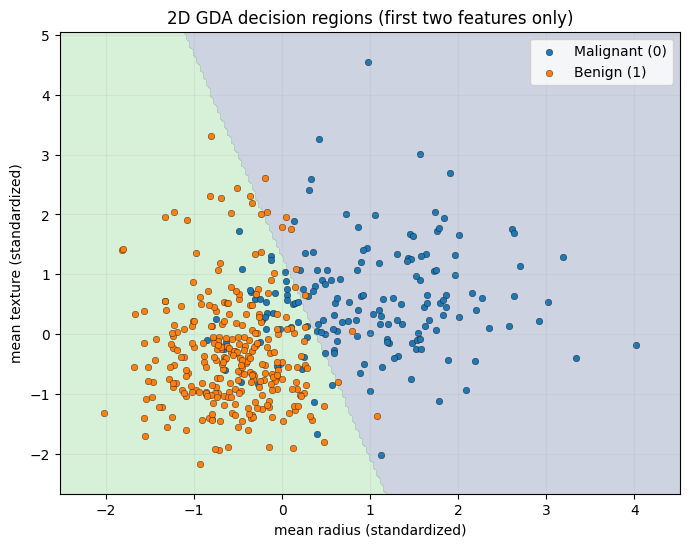

In [8]:
X_train_2d = X_train[:, :2]
plot_gda = GaussianDiscriminantAnalysis().fit(X_train_2d, y_train)
x_min, x_max = X_train_2d[:, 0].min() - 0.5, X_train_2d[:, 0].max() + 0.5
y_min, y_max = X_train_2d[:, 1].min() - 0.5, X_train_2d[:, 1].max() + 0.5

grid_x, grid_y = np.meshgrid(np.linspace(x_min, x_max, 180), np.linspace(y_min, y_max, 180))
grid_points = np.column_stack((grid_x.ravel(), grid_y.ravel()))
grid_predictions = plot_gda.predict(grid_points).reshape(grid_x.shape)

plt.figure(figsize=(8, 6))
plt.contourf(grid_x, grid_y, grid_predictions, alpha=0.25, levels=[-0.5, 0.5, 1.5])
for label, name in [(0, "Malignant (0)"), (1, "Benign (1)")]:
    mask = y_train == label
    plt.scatter(X_train_2d[mask, 0], X_train_2d[mask, 1], label=name, edgecolor="black", linewidth=0.25, s=22)
plt.xlabel(data.feature_names[0] + " (standardized)")
plt.ylabel(data.feature_names[1] + " (standardized)")
plt.title("2D GDA decision regions (first two features only)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [9]:
new_example = X_test[[0]]
scores = gda.predict_log_scores(new_example)[0]
predicted_class = gda.predict(new_example)[0]
print("True label:", y_test[0], "(", data.target_names[y_test[0]], ")")
print("Log score for class 0 (malignant):", round(scores[0], 3))
print("Log score for class 1 (benign):   ", round(scores[1], 3))
print("Predicted class:", predicted_class, "(", data.target_names[predicted_class], ")")

True label: 0 ( malignant )
Log score for class 0 (malignant): -27.28
Log score for class 1 (benign):    -35.603
Predicted class: 0 ( malignant )
